In [1]:
from pathlib import Path
import os, sys
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/common/features.py").is_file())
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.common.features import build_dayahead_table, chronological_split

table = build_dayahead_table("data/nem_weather_halfhourly_2010_2026.csv")
train, validation, _ = chronological_split(table)

In [2]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from harness.dayahead import balanced_accuracy

features = [
    "nsw_price_lag1",
    "nsw_price_lag7",
    "previous_day_mean_price",
    "period",
    "syd_temp",
]

X_val = validation[features]
y_val = validation["y_up"]


def score_predictions(name, predictions):
    return {
        "Model": name,
        "Accuracy (%)": 100 * (y_val == predictions).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(y_val, predictions),
    }


# Calculate both baselines on the same 2014 validation set
baseline_rows = [
    score_predictions("Yesterday baseline", validation["up_lag1"]),
    score_predictions("Last week baseline", validation["up_lag7"]),
]

# Store one result per model for the final summary
model_results = {}


def compare_with_baselines(name, fitted_model):
    predictions = fitted_model.predict(X_val)
    model_results[name] = score_predictions(name, predictions)
    return pd.DataFrame([*baseline_rows, model_results[name]]).round(2)


# Train the selected Gradient Boosting configuration on 2010–2013 data
gb_model = GradientBoostingClassifier(max_depth=4, random_state=42)
gb_model.fit(train[features], train["y_up"])

compare_with_baselines("Gradient Boosting (depth=4)", gb_model)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,Gradient Boosting (depth=4),77.35,77.44


In [3]:
from sklearn.ensemble import RandomForestClassifier

# Train on 2010–2013 data
rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(train[features], train["y_up"])

compare_with_baselines("Random Forest", rf_model)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,Random Forest,77.24,77.21


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

other_features = [col for col in features if col != "period"]

preprocess = ColumnTransformer([
    ("time_slot", OneHotEncoder(handle_unknown="ignore"), ["period"]),
    ("numeric", StandardScaler(), other_features),
])

lr_by_period = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
lr_by_period.fit(train[features], train["y_up"])

compare_with_baselines("Logistic Regression (one-hot period)", lr_by_period)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,Logistic Regression (one-hot period),71.39,71.54


In [5]:
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_preprocess = clone(preprocess).set_params(sparse_threshold=0)
lda_model = make_pipeline(lda_preprocess, LinearDiscriminantAnalysis())

lda_model.fit(train[features], train["y_up"])

compare_with_baselines("LDA (one-hot period)", lda_model)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,LDA (one-hot period),70.11,70.37


In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
)

knn_model.fit(train[features], train["y_up"])

compare_with_baselines("KNN (k=15, numeric period)", knn_model)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,"KNN (k=15, numeric period)",72.69,72.77


In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mlp_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        random_state=42,
    ),
)

mlp_model.fit(train[features], train["y_up"])

compare_with_baselines("MLP (64, 32)", mlp_model)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,"MLP (64, 32)",78.16,78.24


In [8]:
comparison_2014 = (
    pd.DataFrame([*baseline_rows, *model_results.values()])
    .sort_values("Balanced Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)

comparison_2014.style.format({
    "Accuracy (%)": "{:.2f}",
    "Balanced Accuracy (%)": "{:.2f}",
})

,Model,Accuracy (%),Balanced Accuracy (%)
0,"MLP (64, 32)",78.16,78.24
1,Gradient Boosting (depth=4),77.35,77.44
2,Random Forest,77.24,77.21
3,Last week baseline,74.25,74.28
4,Yesterday baseline,73.90,73.99
5,"KNN (k=15, numeric period)",72.69,72.77
6,Logistic Regression (one-hot period),71.39,71.54
7,LDA (one-hot period),70.11,70.37


In [10]:
models = {
    "Gradient Boosting (depth=4)": gb_model,
    "Random Forest": rf_model,
    "Logistic Regression (one-hot period)": lr_by_period,
    "LDA (one-hot period)": lda_model,
    "KNN (k=15, numeric period)": knn_model,
    "MLP (64, 32)": mlp_model,
}

print(f"已准备好 {len(models)} 个模型")

已准备好 6 个模型


In [11]:
from pathlib import Path
from time import perf_counter

import pandas as pd

# chronological_split 的第三个返回值是模拟期
_, _, simulation = chronological_split(table)
simulation = simulation.sort_values(["day", "period"])

# 沿用 2014 验证时的六个已训练模型和相同的特征顺序
daily_outputs = []
start = perf_counter()

for day_number, (day, batch) in enumerate(simulation.groupby("day", sort=True), 1):
    if len(batch) != 48 or batch["period"].nunique() != 48:
        raise ValueError(f"{day} 的半小时数据不完整，请检查后再继续")

    X_day = batch[features]
    output = batch[["day", "period", "y_up"]].copy()

    output["Yesterday baseline"] = batch["up_lag1"]
    output["Last week baseline"] = batch["up_lag7"]

    for name, fitted_model in models.items():
        output[name] = fitted_model.predict(X_day)

    daily_outputs.append(output)

    if day_number == 1 or day_number % 365 == 0:
        minutes = (perf_counter() - start) / 60
        print(f"已完成 {day_number} 天，当前日期 {day:%Y-%m-%d}，耗时 {minutes:.1f} 分钟")

frozen_predictions = pd.concat(daily_outputs, ignore_index=True)

# 保存逐日预测，之后做年度对比时可以直接读取
Path("results").mkdir(exist_ok=True)
frozen_predictions.to_csv("results/price_frozen_predictions.csv", index=False)

print(f"完成，共 {len(daily_outputs)} 天、{len(frozen_predictions):,} 个半小时。")

已完成 1 天，当前日期 2015-01-01，耗时 0.0 分钟
已完成 365 天，当前日期 2015-12-31，耗时 0.9 分钟
已完成 730 天，当前日期 2016-12-30，耗时 1.5 分钟
已完成 1095 天，当前日期 2017-12-30，耗时 2.1 分钟
已完成 1460 天，当前日期 2018-12-30，耗时 2.7 分钟
已完成 1825 天，当前日期 2019-12-30，耗时 3.4 分钟
已完成 2190 天，当前日期 2020-12-29，耗时 4.2 分钟
已完成 2555 天，当前日期 2021-12-29，耗时 4.9 分钟
已完成 2920 天，当前日期 2022-12-29，耗时 5.5 分钟
已完成 3285 天，当前日期 2023-12-29，耗时 6.6 分钟
已完成 3650 天，当前日期 2024-12-28，耗时 7.5 分钟
已完成 4015 天，当前日期 2025-12-28，耗时 8.8 分钟


d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `skle

完成，共 4322 天、207,456 个半小时。


In [12]:
methods = ["Yesterday baseline", "Last week baseline", *models]
actual = frozen_predictions["y_up"]

rows = []
for name in methods:
    pred = frozen_predictions[name]
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

frozen_summary = (
    pd.DataFrame(rows)
    .sort_values("Balanced Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)
frozen_summary.style.format({
    "Accuracy (%)": "{:.2f}",
    "Balanced Accuracy (%)": "{:.2f}",
})

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.81,73.42
1,Last week baseline,70.81,70.42
2,"MLP (64, 32)",69.42,66.73
3,Random Forest,66.17,62.52
4,Gradient Boosting (depth=4),65.69,61.98
5,"KNN (k=15, numeric period)",64.32,61.38
6,Logistic Regression (one-hot period),63.47,61.22
7,LDA (one-hot period),58.39,58.61


In [13]:
p = frozen_predictions.loc[pd.to_datetime(frozen_predictions["day"]).dt.year == 2015]

for name in ["Yesterday baseline", "Last week baseline", "MLP (64, 32)"]:
    print(f"{name}: {balanced_accuracy(p['y_up'], p[name]):.2f}%")

Yesterday baseline: 74.72%
Last week baseline: 72.06%
MLP (64, 32): 75.64%


In [14]:
methods = ["MLP (64, 32)", "Yesterday baseline", "Last week baseline"]
years = pd.to_datetime(frozen_predictions["day"]).dt.year
rows = []

for year, group in frozen_predictions.groupby(years):
    scores = {
        name: balanced_accuracy(group["y_up"], group[name])
        for name in methods
    }
    best_baseline = max(scores["Yesterday baseline"], scores["Last week baseline"])
    rows.append({
        "年份": year,
        **scores,
        "MLP 与较强 baseline 的差距（百分点）": scores["MLP (64, 32)"] - best_baseline,
    })

pd.DataFrame(rows).set_index("年份").style.format("{:.2f}")

,"MLP (64, 32)",Yesterday baseline,Last week baseline,MLP 与较强 baseline 的差距（百分点）
年份,,,,
2015,75.64,74.72,72.06,0.92
2016,69.91,69.83,67.56,0.07
2017,59.86,68.71,68.30,-8.86
2018,65.62,72.26,69.10,-6.64
2019,65.73,71.53,69.10,-5.79
2020,72.41,72.26,69.94,0.15
2021,69.08,72.85,69.26,-3.77
2022,56.22,70.82,67.41,-14.59
2023,66.75,76.00,73.31,-9.26


In [15]:
import holidays
import pandas as pd
from sklearn.base import clone

nsw_holidays = holidays.Australia(subdiv="NSW", years=range(2010, 2027))

def add_public_holiday(data):
    X = data[features].copy()
    target_dates = pd.to_datetime(data["day"]).dt.date
    X["is_public_holiday"] = target_dates.isin(list(nsw_holidays)).astype(int)
    return X

X_train_holiday = add_public_holiday(train)
X_val_holiday = add_public_holiday(validation)

# 只改变输入特征，沿用原版 MLP 的设置
mlp_holiday = clone(mlp_model)
mlp_holiday.fit(X_train_holiday, train["y_up"])

actual = validation["y_up"]
predictions = {
    "Yesterday baseline": validation["up_lag1"],
    "Last week baseline": validation["up_lag7"],
    "MLP (5 features)": mlp_model.predict(validation[features]),
    "MLP (6 features, NSW holiday)": mlp_holiday.predict(X_val_holiday),
}

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.90,73.99
1,Last week baseline,74.25,74.28
2,MLP (5 features),78.16,78.24
3,"MLP (6 features, NSW holiday)",77.19,77.18


In [17]:
import numpy as np
import pandas as pd
from sklearn.base import clone

# 保留原表和原来的 5 个特征，方便复用原版 MLP
table_9 = table.sort_values(["day", "period"]).copy()

# nsw_price_lag1 已经是昨天同一时段的电价
lag1 = table_9["nsw_price_lag1"]

# 对同一预测日的 48 个 lag1 求标准差，即昨天全天的价格波动
table_9["previous_day_price_std"] = lag1.groupby(table_9["day"]).transform("std")

# 固定半小时时段，对 lag1 取最近 7 天均值，覆盖 D-1 到 D-7
table_9["same_period_7day_mean"] = (
    table_9.groupby("period")["nsw_price_lag1"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)

weekday = pd.to_datetime(table_9["day"]).dt.dayofweek
table_9["weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
table_9["weekday_cos"] = np.cos(2 * np.pi * weekday / 7)

features_9 = [
    *features,
    "previous_day_price_std",
    "same_period_7day_mean",
    "weekday_sin",
    "weekday_cos",
]

train_9, val_9, _ = chronological_split(table_9)
train_9 = train_9.dropna(subset=features_9)

# 两个版本使用相同的训练行、验证行和 MLP 设置
actual = val_9["y_up"]
rows = []

for name, columns in [("MLP (5 features)", features), ("MLP (9 features)", features_9)]:
    candidate = clone(mlp_model)
    candidate.fit(train_9[columns], train_9["y_up"])
    pred = candidate.predict(val_9[columns])

    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

    if name == "MLP (9 features)":
        mlp_9 = candidate

pd.DataFrame(rows).round(2)

C:\Users\20695\AppData\Local\Temp\ipykernel_24416\1876286779.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday = pd.to_datetime(table_9["day"]).dt.dayofweek


,Model,Accuracy (%),Balanced Accuracy (%)
0,MLP (5 features),77.85,77.98
1,MLP (9 features),79.28,79.32


In [18]:
from sklearn.base import clone

data = table_9.copy()

# 共用表可能用 nsw_demand_lag1，而 starter notebook 用 demand_lag1
for lag in (1, 7):
    name = f"demand_lag{lag}"
    alias = f"nsw_demand_lag{lag}"
    if name not in data:
        if alias in data:
            data[name] = data[alias]
        else:
            # 按时间戳取同一半小时的历史需求
            past_time = data.index - pd.Timedelta(days=lag)
            data[name] = data["y_demand"].reindex(past_time).to_numpy()

lag_features = ["demand_lag1", "demand_lag7", "up_lag1", "up_lag7"]
features_13 = features_9 + lag_features

# 只选明确属于过去的跨州变量
interstate_lags = [
    f"{state}_{variable}_lag{lag}"
    for state in ("vic", "qld")
    for variable in ("price", "demand")
    for lag in (1, 7)
    if f"{state}_{variable}_lag{lag}" in data.columns
]

feature_sets = {
    "MLP (5 features)": features,
    "MLP (9 features)": features_9,
    "MLP (13 features, NSW lags)": features_13,
}
if interstate_lags:
    feature_sets["MLP (NSW + interstate lags)"] = features_13 + interstate_lags

train_part, val_part, _ = chronological_split(data)
all_features = features_13 + interstate_lags
train_part = train_part.dropna(subset=all_features)
val_part = val_part.dropna(subset=all_features)
actual = val_part["y_up"]

predictions = {
    "Yesterday baseline": val_part["up_lag1"],
    "Last week baseline": val_part["up_lag7"],
}
fitted_mlps = {}

for name, columns in feature_sets.items():
    candidate = clone(mlp_model)
    candidate.fit(train_part[columns], train_part["y_up"])
    fitted_mlps[name] = candidate
    predictions[name] = candidate.predict(val_part[columns])

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Features": len(feature_sets[name]) if name in feature_sets else "—",
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows).sort_values("Balanced Accuracy (%)", ascending=False).round(2)

d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\Anaconda3\envs\comp9417\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Features,Accuracy (%),Balanced Accuracy (%)
3,MLP (9 features),9,79.28,79.32
2,MLP (5 features),5,77.85,77.98
4,"MLP (13 features, NSW lags)",13,77.70,77.74
5,MLP (NSW + interstate lags),21,76.35,76.21
1,Last week baseline,—,74.25,74.28
0,Yesterday baseline,—,73.90,73.99


In [19]:
from sklearn.base import clone

features_15 = features_13 + ["mel_temp", "bne_temp"]
features_19 = features_15 + [
    "vic_price_lag1",
    "vic_price_lag7",
    "qld_price_lag1",
    "qld_price_lag7",
]

new_feature_sets = {
    "MLP (15 features, + MEL/BNE temp)": features_15,
    "MLP (19 features, + VIC/QLD prices)": features_19,
}

actual = val_part["y_up"]

for name, columns in new_feature_sets.items():
    candidate = clone(mlp_model)
    candidate.fit(train_part[columns], train_part["y_up"])

    fitted_mlps[name] = candidate
    feature_sets[name] = columns
    predictions[name] = candidate.predict(val_part[columns])

# 汇总已有模型、新模型和两个 baseline
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Features": len(feature_sets[name]) if name in feature_sets else "—",
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

comparison_2014 = (
    pd.DataFrame(rows)
    .sort_values("Balanced Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)
comparison_2014.round(2)

,Model,Features,Accuracy (%),Balanced Accuracy (%)
0,MLP (9 features),9,79.28,79.32
1,MLP (5 features),5,77.85,77.98
2,"MLP (13 features, NSW lags)",13,77.70,77.74
3,"MLP (15 features, + MEL/BNE temp)",15,77.35,77.24
4,"MLP (19 features, + VIC/QLD prices)",19,77.39,77.24
5,MLP (NSW + interstate lags),21,76.35,76.21
6,Last week baseline,—,74.25,74.28
7,Yesterday baseline,—,73.90,73.99


In [20]:
from xgboost import XGBClassifier

X_train = train_part[features_9]
y_train = train_part["y_up"]
X_val = val_part[features_9]
y_val = val_part["y_up"]

# 第一轮固定这组参数，先比较模型
xgb_9 = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)
xgb_9.fit(X_train, y_train)

mlp_9 = fitted_mlps["MLP (9 features)"]
val_predictions = {
    "Yesterday baseline": val_part["up_lag1"],
    "Last week baseline": val_part["up_lag7"],
    "MLP (9 features)": mlp_9.predict(X_val),
    "XGBoost (9 features)": xgb_9.predict(X_val),
}

rows = []
for name, pred in val_predictions.items():
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (y_val == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(y_val, pred),
    })

pd.DataFrame(rows).sort_values(
    "Balanced Accuracy (%)", ascending=False
).reset_index(drop=True).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
0,XGBoost (9 features),79.42,79.51
1,MLP (9 features),79.28,79.32
2,Last week baseline,74.25,74.28
3,Yesterday baseline,73.90,73.99


In [21]:
p_xgb = xgb_9.predict_proba(X_val)[:, 1]
p_mlp = mlp_9.predict_proba(X_val)[:, 1]
ensemble_pred = ((p_xgb + p_mlp) / 2 >= 0.5).astype(int)

ensemble_row = {
    "Model": "XGBoost + MLP (50/50)",
    "Accuracy (%)": 100 * (y_val == ensemble_pred).mean(),
    "Balanced Accuracy (%)": balanced_accuracy(y_val, ensemble_pred),
}

comparison = pd.DataFrame([*rows, ensemble_row])
comparison.sort_values(
    "Balanced Accuracy (%)", ascending=False
).reset_index(drop=True).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
0,XGBoost + MLP (50/50),80.08,80.15
1,XGBoost (9 features),79.42,79.51
2,MLP (9 features),79.28,79.32
3,Last week baseline,74.25,74.28
4,Yesterday baseline,73.90,73.99


In [22]:
from sklearn.base import clone
import pandas as pd

actual = val_part["y_up"]
xgb_feature_models = {}
xgb_rows = []

for group_name, columns in feature_sets.items():
    if list(columns) == list(features_9):
        fitted_xgb = xgb_9
    else:
        fitted_xgb = clone(xgb_9)
        fitted_xgb.fit(train_part[columns], train_part["y_up"])

    xgb_feature_models[group_name] = fitted_xgb

    # 两个模型使用相同的特征、相同的 2014 验证行
    X_compare = val_part[columns]
    xgb_pred = fitted_xgb.predict(X_compare)
    mlp_pred = fitted_mlps[group_name].predict(X_compare)

    xgb_ba = balanced_accuracy(actual, xgb_pred)
    mlp_ba = balanced_accuracy(actual, mlp_pred)

    xgb_rows.append({
        "Feature set": group_name.removeprefix("MLP "),
        "Features": len(columns),
        "XGB Accuracy (%)": 100 * (actual == xgb_pred).mean(),
        "XGB Balanced Accuracy (%)": xgb_ba,
        "MLP Balanced Accuracy (%)": mlp_ba,
        "XGB − MLP (百分点)": xgb_ba - mlp_ba,
    })

xgb_feature_comparison = (
    pd.DataFrame(xgb_rows)
    .sort_values("XGB Balanced Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)

xgb_feature_comparison.round(2)

,Feature set,Features,XGB Accuracy (%),XGB Balanced Accuracy (%),MLP Balanced Accuracy (%),XGB − MLP (百分点)
0,"(15 features, + MEL/BNE temp)",15,80.44,80.46,77.24,3.21
1,"(19 features, + VIC/QLD prices)",19,80.43,80.43,77.24,3.19
2,"(13 features, NSW lags)",13,80.20,80.24,77.74,2.50
3,(NSW + interstate lags),21,80.22,80.22,76.21,4.00
4,(9 features),9,79.42,79.51,79.32,0.18
5,(5 features),5,77.55,77.62,77.98,-0.37


In [23]:
xgb_15 = xgb_feature_models["MLP (15 features, + MEL/BNE temp)"]
mlp_9 = fitted_mlps["MLP (9 features)"]

p_xgb = xgb_15.predict_proba(val_part[features_15])[:, 1]
p_mlp = mlp_9.predict_proba(val_part[features_9])[:, 1]
actual = val_part["y_up"]

predictions_2014 = {
    "XGBoost (15 features)": xgb_15.predict(val_part[features_15]),
    "MLP (9 features)": mlp_9.predict(val_part[features_9]),
    "XGBoost (15) + MLP (9), 50/50": ((p_xgb + p_mlp) / 2 >= 0.5).astype(int),
}

rows = []
for name, pred in predictions_2014.items():
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows).sort_values("Balanced Accuracy (%)", ascending=False).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
2,"XGBoost (15) + MLP (9), 50/50",80.66,80.71
0,XGBoost (15 features),80.44,80.46
1,MLP (9 features),79.28,79.32


In [24]:
from pathlib import Path

import pandas as pd
from harness.dayahead import balanced_accuracy

_, _, sim = chronological_split(data)
sim = sim.sort_values(["day", "period"])

ensemble_name = "XGBoost (15) + MLP (9), 50/50"
daily_results = []

for n, (day, batch) in enumerate(sim.groupby("day", sort=True), start=1):
    if len(batch) != 48 or batch["period"].nunique() != 48:
        raise ValueError(f"{day:%Y-%m-%d} 的半小时时段不完整")

    # 两个模型各用训练时的特征和列顺序
    X_xgb = batch[features_15]
    X_mlp = batch[features_9]

    p_xgb = xgb_15.predict_proba(X_xgb)[:, 1]
    p_mlp = mlp_9.predict_proba(X_mlp)[:, 1]

    result = batch[["day", "period", "y_up"]].copy()
    result["Yesterday baseline"] = batch["up_lag1"]
    result["Last week baseline"] = batch["up_lag7"]
    result["XGBoost (15 features)"] = xgb_15.predict(X_xgb)
    result["MLP (9 features)"] = mlp_9.predict(X_mlp)
    result[ensemble_name] = ((p_xgb + p_mlp) / 2 >= 0.5).astype(int)
    daily_results.append(result)

    if n % 365 == 0:
        print(f"已完成 {n} 天，当前日期 {day:%Y-%m-%d}")

frozen_ensemble = pd.concat(daily_results, ignore_index=True)

# 使用新文件名，保留之前的 5 特征模型结果
output_path = Path("results/price_frozen_xgb15_mlp9.csv")
output_path.parent.mkdir(exist_ok=True)
frozen_ensemble.to_csv(output_path, index=False)

print(f"已保存 {len(daily_results):,} 天、{len(frozen_ensemble):,} 条预测到 {output_path}")

actual = frozen_ensemble["y_up"]
methods = [
    ensemble_name,
    "XGBoost (15 features)",
    "MLP (9 features)",
    "Yesterday baseline",
    "Last week baseline",
]

rows = []
for name in methods:
    pred = frozen_ensemble[name]
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

frozen_summary = (
    pd.DataFrame(rows)
    .sort_values("Balanced Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)
frozen_summary.round(2)

已完成 365 天，当前日期 2015-12-31
已完成 730 天，当前日期 2016-12-30
已完成 1095 天，当前日期 2017-12-30
已完成 1460 天，当前日期 2018-12-30
已完成 1825 天，当前日期 2019-12-30
已完成 2190 天，当前日期 2020-12-29
已完成 2555 天，当前日期 2021-12-29
已完成 2920 天，当前日期 2022-12-29
已完成 3285 天，当前日期 2023-12-29
已完成 3650 天，当前日期 2024-12-28
已完成 4015 天，当前日期 2025-12-28
已保存 4,322 天、207,456 条预测到 results\price_frozen_xgb15_mlp9.csv


,Model,Accuracy (%),Balanced Accuracy (%)
0,Yesterday baseline,73.81,73.42
1,Last week baseline,70.81,70.42
2,XGBoost (15 features),68.33,64.50
3,"XGBoost (15) + MLP (9), 50/50",65.31,61.03
4,MLP (9 features),64.18,60.00


In [28]:
from sklearn.base import clone

def relative_price_features(frame):
    X = frame[features_15].copy()
    mean_price = X["previous_day_mean_price"]
    # 昨日价格几乎不变时，用 1 AUD/MWh 作为分母下限
    scale = X["previous_day_price_std"].clip(lower=1.0)

    price_columns = ["nsw_price_lag1", "nsw_price_lag7", "same_period_7day_mean"]
    for col in price_columns:
        X[f"{col}_relative"] = (X[col] - mean_price) / scale

    return X.drop(columns=price_columns + ["previous_day_mean_price"])

X_train_relative = relative_price_features(train_part)
X_val_relative = relative_price_features(val_part)

xgb_relative = clone(xgb_15)
xgb_relative.fit(X_train_relative, train_part["y_up"])

actual = val_part["y_up"]
predictions_relative = {
    "Yesterday baseline": val_part["up_lag1"],
    "Last week baseline": val_part["up_lag7"],
    "XGBoost (original 15 features)": xgb_15.predict(val_part[features_15]),
    "XGBoost (relative prices)": xgb_relative.predict(X_val_relative),
}

rows_relative = []
for name, pred in predictions_relative.items():
    rows_relative.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows_relative).sort_values(
    "Balanced Accuracy (%)", ascending=False
).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
3,XGBoost (relative prices),80.48,80.47
2,XGBoost (original 15 features),80.44,80.46
1,Last week baseline,74.25,74.28
0,Yesterday baseline,73.90,73.99


In [ ]:
new_name = "XGBoost (relative prices)"
daily_relative = []

for day, batch in sim.groupby("day", sort=True):
    result = batch[["day", "period"]].copy()
    result[new_name] = xgb_relative.predict(relative_price_features(batch))
    daily_relative.append(result)

# 按日期和半小时时段对齐，确保每个模型比较的是同一条记录
relative_frozen = frozen_ensemble.merge(
    pd.concat(daily_relative, ignore_index=True),
    on=["day", "period"],
    how="left",
    validate="one_to_one",
)
assert relative_frozen[new_name].notna().all(), "有时段缺少新版模型的预测"

actual = relative_frozen["y_up"]
methods = [
    new_name,
    "XGBoost (15 features)",
    ensemble_name,
    "Yesterday baseline",
    "Last week baseline",
]

rows = []
for name in methods:
    pred = relative_frozen[name]
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows).sort_values("Balanced Accuracy (%)", ascending=False).round(2)

In [30]:
import pandas as pd
from sklearn.base import clone
from harness.dayahead import balanced_accuracy

frozen_col = "XGBoost (relative prices)"
updated_col = "XGBoost (relative prices, retrain every 2 years)"
keys = ["day", "period"]

# 2015 年还没有重训，两种策略的预测应完全相同
first_year = relative_frozen.loc[
    relative_frozen["day"] < "2016-01-01", keys + [frozen_col]
].rename(columns={frozen_col: updated_col})

parts = [first_year]

for update_no, year in enumerate(range(2016, 2027, 2), start=1):
    start = pd.Timestamp(year, 1, 1)
    end = start + pd.DateOffset(years=2)
    window_start = start - pd.DateOffset(years=2)

    # 例如，2016 年初只用 2014–2015 年的已知数据训练
    window = data.loc[
        (data["day"] >= window_start) & (data["day"] < start)
    ].dropna(subset=features_15 + ["y_up"])

    updated_model = clone(xgb_relative)
    updated_model.fit(relative_price_features(window), window["y_up"])

    period = sim.loc[(sim["day"] >= start) & (sim["day"] < end)]
    for day, batch in period.groupby("day", sort=True):
        result = batch[keys].copy()
        result[updated_col] = updated_model.predict(relative_price_features(batch))
        parts.append(result)

    print(f"完成 {update_no}/6：用 {year-2}–{year-1} 年训练，预测到 {period['day'].max():%Y-%m-%d}")

# 按预测日和半小时时段对齐，确保所有策略比较的是同一批记录
relative_adapted = relative_frozen.merge(
    pd.concat(parts, ignore_index=True),
    on=keys,
    how="left",
    validate="one_to_one",
)
assert relative_adapted[updated_col].notna().all(), "有半小时时段缺少重训版预测"

actual = relative_adapted["y_up"]
frozen_ba = balanced_accuracy(actual, relative_adapted[frozen_col])

rows = []
for name in [updated_col, frozen_col, "Yesterday baseline", "Last week baseline"]:
    pred = relative_adapted[name]
    ba = balanced_accuracy(actual, pred)
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": ba,
        "比冻结 XGBoost 高多少（百分点）": ba - frozen_ba,
    })

pd.DataFrame(rows).sort_values("Balanced Accuracy (%)", ascending=False).round(2)

完成 1/6：用 2014–2015 年训练，预测到 2017-12-31
完成 2/6：用 2016–2017 年训练，预测到 2019-12-31
完成 3/6：用 2018–2019 年训练，预测到 2021-12-31
完成 4/6：用 2020–2021 年训练，预测到 2023-12-31
完成 5/6：用 2022–2023 年训练，预测到 2025-12-31
完成 6/6：用 2024–2025 年训练，预测到 2026-10-31


,Model,Accuracy (%),Balanced Accuracy (%),比冻结 XGBoost 高多少（百分点）
0,"XGBoost (relative prices, retrain every 2 years)",77.70,76.64,8.20
2,Yesterday baseline,73.81,73.42,4.98
3,Last week baseline,70.81,70.42,1.97
1,XGBoost (relative prices),71.42,68.44,0.00


In [31]:
import pandas as pd
from harness.dayahead import balanced_accuracy

def relative_ensemble_predict(frame):
    p_xgb = xgb_relative.predict_proba(relative_price_features(frame))[:, 1]
    p_mlp = mlp_9.predict_proba(frame[features_9])[:, 1]
    return ((p_xgb + p_mlp) / 2 >= 0.5).astype(int)

original_name = "原版 XGBoost + MLP (50/50)"
relative_name = "相对电价 XGBoost"
new_name = "相对电价 XGBoost + MLP (50/50)"

# 2014 验证：同一个 MLP，只替换集成里的 XGBoost
p_xgb_original = xgb_15.predict_proba(val_part[features_15])[:, 1]
p_mlp = mlp_9.predict_proba(val_part[features_9])[:, 1]

val_preds = {
    original_name: ((p_xgb_original + p_mlp) / 2 >= 0.5).astype(int),
    relative_name: xgb_relative.predict(relative_price_features(val_part)),
    new_name: relative_ensemble_predict(val_part),
    "Yesterday baseline": val_part["up_lag1"],
    "Last week baseline": val_part["up_lag7"],
}

# 全期冻结：逐日计算新集成，复用其他模型已保存的预测
parts = []
for day, batch in sim.groupby("day", sort=True):
    result = batch[["day", "period"]].copy()
    result[new_name] = relative_ensemble_predict(batch)
    parts.append(result)

ensemble_check = relative_frozen.merge(
    pd.concat(parts, ignore_index=True),
    on=["day", "period"],
    how="left",
    validate="one_to_one",
)
assert ensemble_check[new_name].notna().all(), "有时段缺少新集成预测"

frozen_preds = {
    original_name: ensemble_check[ensemble_name],
    relative_name: ensemble_check["XGBoost (relative prices)"],
    new_name: ensemble_check[new_name],
    "Yesterday baseline": ensemble_check["Yesterday baseline"],
    "Last week baseline": ensemble_check["Last week baseline"],
}

rows = []
for name in val_preds:
    rows.append({
        "Model": name,
        "2014 验证 BA (%)": balanced_accuracy(val_part["y_up"], val_preds[name]),
        "全期冻结 BA (%)": balanced_accuracy(ensemble_check["y_up"], frozen_preds[name]),
    })

pd.DataFrame(rows).round(2)

,Model,2014 验证 BA (%),全期冻结 BA (%)
0,原版 XGBoost + MLP (50/50),80.71,61.03
1,相对电价 XGBoost,80.47,68.44
2,相对电价 XGBoost + MLP (50/50),80.55,61.55
3,Yesterday baseline,73.99,73.42
4,Last week baseline,74.28,70.42


In [33]:
import numpy as np

def predict_with_yesterday(model, X):
    up_col = list(model.classes_).index(1)
    p_up = model.predict_proba(X)[:, up_col]
    pred = X["up_lag1"].to_numpy(copy=True)

    pred[p_up >= 0.70] = 1
    pred[p_up <= 0.30] = 0
    return pred

In [38]:
from sklearn.base import clone
xgb_relative_d3 = clone(xgb_relative).set_params(max_depth=3)

In [40]:
xgb_relative_d3.fit(
    relative_price_features(train_part),
    train_part["y_up"]
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [42]:
from sklearn.base import clone
import pandas as pd

X_train = relative_price_features(train_part)
y_train = train_part["y_up"]
X_val = relative_price_features(val_part)
y_val = val_part["y_up"]

tuned_models = {}
rows = []

for depth in [2, 3, 4]:
    for weight in [1, 5]:
        candidate = clone(xgb_relative).set_params(
            max_depth=depth,
            min_child_weight=weight,
        )
        candidate.fit(X_train, y_train)
        pred = candidate.predict(X_val)

        tuned_models[(depth, weight)] = candidate
        rows.append({
            "Max depth": depth,
            "Min child weight": weight,
            "Accuracy (%)": 100 * (y_val == pred).mean(),
            "Balanced Accuracy (%)": balanced_accuracy(y_val, pred),
        })

tuning_2014 = pd.DataFrame(rows).sort_values(
    "Balanced Accuracy (%)", ascending=False
).reset_index(drop=True)

tuning_2014.round(2)

,Max depth,Min child weight,Accuracy (%),Balanced Accuracy (%)
0,4,1,80.48,80.47
1,3,5,80.45,80.44
2,4,5,80.29,80.29
3,3,1,80.27,80.26
4,2,5,79.83,79.83
5,2,1,79.83,79.83


In [44]:
daily_results = []

for day, batch in sim.sort_values(["day", "period"]).groupby("day"):
    X_day = relative_price_features(batch)

    result = batch[["y_up"]].copy()
    result["XGBoost 原版 (4, 1)"] = tuned_models[(4, 1)].predict(X_day)
    result["XGBoost 调参 (3, 5)"] = tuned_models[(3, 5)].predict(X_day)
    result["Yesterday baseline"] = batch["up_lag1"]
    result["Last week baseline"] = batch["up_lag7"]
    daily_results.append(result)

frozen_check = pd.concat(daily_results, ignore_index=True)
actual = frozen_check["y_up"]

rows = []
for name in frozen_check.columns.drop("y_up"):
    pred = frozen_check[name]
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

pd.DataFrame(rows).sort_values("Balanced Accuracy (%)", ascending=False).round(2)

,Model,Accuracy (%),Balanced Accuracy (%)
2,Yesterday baseline,73.81,73.42
3,Last week baseline,70.81,70.42
1,"XGBoost 调参 (3, 5)",72.28,69.60
0,"XGBoost 原版 (4, 1)",71.42,68.44


In [45]:
from sklearn.base import clone

def relative_features_with_rank(frame):
    X = relative_price_features(frame).copy()
    X["yesterday_price_rank"] = (
        frame.groupby("day")["nsw_price_lag1"]
        .rank(method="average", pct=True)
    )
    return X

# 沿用刚才的 (3, 5) 参数和同一份训练数据
xgb_rank = clone(tuned_models[(3, 5)])
xgb_rank.fit(relative_features_with_rank(train_part), train_part["y_up"])

y = val_part["y_up"]
predictions = {
    "XGBoost (3, 5)": tuned_models[(3, 5)].predict(relative_price_features(val_part)),
    "XGBoost (3, 5) + 昨日电价排名": xgb_rank.predict(relative_features_with_rank(val_part)),
    "Yesterday baseline": val_part["up_lag1"],
    "Last week baseline": val_part["up_lag7"],
}

pd.DataFrame([
    {
        "Model": name,
        "Accuracy (%)": 100 * (y == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(y, pred),
    }
    for name, pred in predictions.items()
]).round(2)


,Model,Accuracy (%),Balanced Accuracy (%)
0,"XGBoost (3, 5)",80.45,80.44
1,"XGBoost (3, 5) + 昨日电价排名",80.46,80.45
2,Yesterday baseline,73.90,73.99
3,Last week baseline,74.25,74.28


In [51]:
import pandas as pd
from sklearn.base import clone

# 已训练好的相对电价 XGBoost，不加昨日电价排名
frozen_model = tuned_models[(3, 5)]
periodic_model = frozen_model

# 用之前实验中的同一批数据
sim_sorted = sim.sort_values(["day", "period"]).copy()
history = pd.concat([train_part, val_part, sim_sorted], ignore_index=True)
history_year = pd.to_datetime(history["day"]).dt.year

retrain_years = {2016, 2018, 2020, 2022, 2024, 2026}
retrained = set()
retrain_log = []
daily_predictions = []

for day, batch in sim_sorted.groupby("day", sort=True):
    year = pd.Timestamp(day).year

    # 在该年的第一个模拟日预测前更新，只使用此前两年的数据
    if year in retrain_years and year not in retrained:
        recent = history.loc[history_year.between(year - 2, year - 1)]
        periodic_model = clone(frozen_model)
        periodic_model.fit(relative_price_features(recent), recent["y_up"])
        retrained.add(year)

        retrain_log.append({
            "新模型开始预测": pd.Timestamp(day).date(),
            "训练起始日": pd.to_datetime(recent["day"]).min().date(),
            "训练截止日": pd.to_datetime(recent["day"]).max().date(),
            "训练样本数": len(recent),
        })

    X_day = relative_price_features(batch)
    out = batch[["day", "period", "y_up"]].copy()
    out["XGBoost (3, 5) 全期冻结"] = frozen_model.predict(X_day)
    out["XGBoost (3, 5) 每两年重训"] = periodic_model.predict(X_day)
    out["Yesterday baseline"] = batch["up_lag1"]
    out["Last week baseline"] = batch["up_lag7"]
    daily_predictions.append(out)

periodic_35_predictions = pd.concat(daily_predictions, ignore_index=True)
actual = periodic_35_predictions["y_up"]
frozen_ba = balanced_accuracy(actual, periodic_35_predictions["XGBoost (3, 5) 全期冻结"])
yesterday_ba = balanced_accuracy(actual, periodic_35_predictions["Yesterday baseline"])

rows = []
for name in periodic_35_predictions.columns.drop(["day", "period", "y_up"]):
    pred = periodic_35_predictions[name]
    ba = balanced_accuracy(actual, pred)
    rows.append({
        "模型 / 策略": name,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": ba,
        "比冻结版高（百分点）": ba - frozen_ba,
        "比 Yesterday 高（百分点）": ba - yesterday_ba,
    })

periodic_35_summary = pd.DataFrame(rows)
print(f"共重训 {len(retrain_log)} 次")
display(pd.DataFrame(retrain_log))
display(periodic_35_summary.round(2))

共重训 6 次


,新模型开始预测,训练起始日,训练截止日,训练样本数
0,2016-01-01,2014-01-01,2015-12-31,35040
1,2018-01-01,2016-01-01,2017-12-31,35088
2,2020-01-01,2018-01-01,2019-12-31,35040
3,2022-01-01,2020-01-01,2021-12-31,35088
4,2024-01-01,2022-01-01,2023-12-31,35040
5,2026-01-01,2024-01-01,2025-12-31,35088


,模型 / 策略,Accuracy (%),Balanced Accuracy (%),比冻结版高（百分点）,比 Yesterday 高（百分点）
0,"XGBoost (3, 5) 全期冻结",72.28,69.60,0.00,-3.82
1,"XGBoost (3, 5) 每两年重训",77.72,76.62,7.02,3.20
2,Yesterday baseline,73.81,73.42,3.82,0.00
3,Last week baseline,70.81,70.42,0.82,-3.00


In [52]:
from collections import deque

import pandas as pd
from sklearn.base import clone

base_model = tuned_models[(3, 5)]
window = 30
budget = 6

# 只用 2014 验证期设定阈值
val_pred = base_model.predict(relative_price_features(val_part))
val_errors = pd.DataFrame({
    "day": pd.to_datetime(val_part["day"]).dt.normalize().to_numpy(),
    "error": val_pred != val_part["y_up"].to_numpy(),
})
daily_val_error = val_errors.groupby("day")["error"].mean()
threshold = daily_val_error.rolling(window).mean().dropna().quantile(0.95)

# 预测、监测、重训按日期顺序进行
history = pd.concat([train_part, val_part, sim], ignore_index=True)
history_day = pd.to_datetime(history["day"]).dt.normalize()
sim_sorted = sim.sort_values(["day", "period"])
last_day = pd.Timestamp(sim_sorted["day"].max()).normalize()

drift_model = base_model
recent_errors = deque(maxlen=window)
above_threshold = False
updates = 0
signals = []
daily_predictions = []

for day, batch in sim_sorted.groupby("day", sort=True):
    day = pd.Timestamp(day).normalize()

    # 先用当前模型预测当天，保存结果后才观察真实标签
    pred = drift_model.predict(relative_price_features(batch))
    part = batch[["day", "period"]].copy()
    part["相对电价 XGBoost：误差触发重训"] = pred
    daily_predictions.append(part)

    recent_errors.append((pred != batch["y_up"].to_numpy()).mean())
    if len(recent_errors) < window:
        continue

    error_30d = sum(recent_errors) / window
    crossed = error_30d > threshold and not above_threshold
    above_threshold = error_30d > threshold

    if crossed:
        next_day = day + pd.Timedelta(days=1)
        do_update = updates < budget and next_day <= last_day
        signals.append({
            "信号日期": day.date(),
            "近30天错误率 (%)": 100 * error_30d,
            "执行重训": do_update,
            "生效日期": next_day.date() if do_update else None,
        })

        if do_update:
            start = next_day - pd.DateOffset(years=2)
            recent = history.loc[history_day.between(start, day)]
            drift_model = clone(base_model)
            drift_model.fit(relative_price_features(recent), recent["y_up"])
            updates += 1

            # 更新后重新累计新模型的误差
            recent_errors.clear()
            above_threshold = False

# 按日期和时段对齐，确保所有策略评估相同的样本
drift_name = "相对电价 XGBoost：误差触发重训"
stage2_predictions = periodic_35_predictions.merge(
    pd.concat(daily_predictions, ignore_index=True),
    on=["day", "period"], how="left", validate="one_to_one",
)
assert stage2_predictions[drift_name].notna().all()

actual = stage2_predictions["y_up"]
strategies = [
    ("相对电价 XGBoost：全期冻结", "XGBoost (3, 5) 全期冻结", 0),
    ("相对电价 XGBoost：每两年重训", "XGBoost (3, 5) 每两年重训", len(retrain_log)),
    (drift_name, drift_name, updates),
    ("Yesterday baseline", "Yesterday baseline", 0),
    ("Last week baseline", "Last week baseline", 0),
]

rows = []
for name, column, count in strategies:
    pred = stage2_predictions[column]
    rows.append({
        "模型 / 策略": name,
        "重训次数": count,
        "Accuracy (%)": 100 * (actual == pred).mean(),
        "Balanced Accuracy (%)": balanced_accuracy(actual, pred),
    })

print(f"2014 确定的报警阈值：30 天平均错误率超过 {threshold:.2%}")
print(f"模拟期共发出 {len(signals)} 次信号，实际重训 {updates} 次")
display(pd.DataFrame(signals).round(2))
display(pd.DataFrame(rows).round(2))

2014 确定的报警阈值：30 天平均错误率超过 24.06%
模拟期共发出 86 次信号，实际重训 6 次


,信号日期,近30天错误率 (%),执行重训,生效日期
0,2015-09-23,24.51,True,2015-09-24
1,2015-10-25,24.10,True,2015-10-26
2,2015-12-21,24.17,True,2015-12-22
3,2016-03-19,24.58,True,2016-03-20
4,2016-04-18,30.07,True,2016-04-19
...,...,...,...,...
81,2025-07-25,24.51,False,None
82,2025-08-07,25.97,False,None
83,2025-08-18,25.69,False,None
84,2025-09-01,24.44,False,None


,模型 / 策略,重训次数,Accuracy (%),Balanced Accuracy (%)
0,相对电价 XGBoost：全期冻结,0,72.28,69.60
1,相对电价 XGBoost：每两年重训,6,77.72,76.62
2,相对电价 XGBoost：误差触发重训,6,73.11,71.17
3,Yesterday baseline,0,73.81,73.42
4,Last week baseline,0,70.81,70.42


In [53]:
import pandas as pd

# 只读取预测前已经知道的输入特征
def daily_up_share(frame):
    day = pd.to_datetime(frame["day"]).dt.normalize()
    return frame["up_lag1"].groupby(day).mean().sort_index()

reference = daily_up_share(val_part)
simulation = daily_up_share(sim)

# 用 2014 年确定上下限，整个模拟期使用同一组阈值
reference_30d = reference.rolling(30).mean().dropna()
lower, upper = reference_30d.quantile([0.025, 0.975])

# 接上 2014 年末的数据，使 2015 年第一天就有完整的历史窗口
all_days = pd.concat([reference, simulation]).sort_index()
rolling_share = all_days.rolling(30).mean()
outside = (rolling_share < lower) | (rolling_share > upper)

input_daily = pd.DataFrame(index=simulation.index)
input_daily["30天正类占比 (%)"] = 100 * rolling_share
input_daily["超出参考范围"] = outside
# 连续多天越界只记录一次报警
input_daily["输入漂移报警"] = outside & ~outside.shift(1, fill_value=False)

# 用已保存的冻结预测做事后对照
preds = stage2_predictions.copy()
preds["日期"] = pd.to_datetime(preds["day"]).dt.normalize()
preds["预测正确"] = preds["XGBoost (3, 5) 全期冻结"].eq(preds["y_up"])
input_daily["冻结模型当日 Accuracy (%)"] = (
    100 * preds.groupby("日期")["预测正确"].mean()
)

# 对齐上一格误差检测器的报警日。它监测的是部署中的模型
error_signal_days = pd.to_datetime(
    [record["信号日期"] for record in signals]
).normalize()
input_daily["误差漂移报警"] = input_daily.index.isin(error_signal_days)
input_daily.index.name = "日期"

# 报告表 1：比较处于参考范围内和范围外的全部日子
status = input_daily["超出参考范围"].map(
    {False: "输入在参考范围内", True: "输入超出参考范围"}
)
input_summary = (
    input_daily.groupby(status)["冻结模型当日 Accuracy (%)"]
    .agg(["size", "mean"])
    .rename(columns={"size": "天数", "mean": "冻结模型平均 Accuracy (%)"})
)

# 报告表 2：保留两类检测器的具体报警日期
signal_dates = input_daily.loc[
    input_daily["输入漂移报警"] | input_daily["误差漂移报警"]
]

print(f"2014 年参考范围：{lower:.2%} 至 {upper:.2%}")
print(f"输入漂移报警 {input_daily['输入漂移报警'].sum()} 次")
print(f"误差漂移报警 {input_daily['误差漂移报警'].sum()} 次")
display(input_summary.round(2))
display(signal_dates.round(2))

2014 年参考范围：38.68% 至 64.58%
输入漂移报警 40 次
误差漂移报警 86 次


,天数,冻结模型平均 Accuracy (%)
超出参考范围,,
输入在参考范围内,3424,70.81
输入超出参考范围,898,77.89


,30天正类占比 (%),超出参考范围,输入漂移报警,冻结模型当日 Accuracy (%),误差漂移报警
日期,,,,,
2015-08-06,38.61,True,True,93.75,False
2015-09-02,37.92,True,True,77.08,False
2015-09-10,38.61,True,True,45.83,False
2015-09-17,38.54,True,True,66.67,False
2015-09-22,38.40,True,True,66.67,False
...,...,...,...,...,...
2025-07-25,42.22,False,False,70.83,True
2025-08-07,45.69,False,False,66.67,True
2025-08-18,45.28,False,False,52.08,True


Accuracy (%)                                    \
Strategy Error-triggered retraining Frozen XGBoost Last week baseline   
Year                                                                    
2015                          79.32          79.29              72.36   
2016                          75.37          75.29              68.67   
2017                          75.99          75.03              68.65   
2018                          78.01          76.99              69.95   
2019                          77.56          76.58              69.47   
2020                          76.97          77.25              71.03   
2021                          73.36          73.26              69.95   
2022                          64.25          63.94              67.51   
2023                          69.96          67.96              73.49   
2024                          69.29          69.14              72.85   
2025                          69.20          67.35              75.50   
2026                          67.01          63.90              70.14   

                                                     Balanced Accuracy (%)  \
Strategy Periodic retraining Yesterday baseline Error-triggered retraining   
Year                                                                         
2015                   79.29              74.79                      78.99   
2016                   75.05              71.10                      73.05   
2017                   75.44              69.26                      74.86   
2018                   78.67              73.33                      76.67   
2019                   78.47              72.48                      75.89   
2020                   77.66              73.79                      74.54   
2021                   75.79              73.87                      70.38   
2022                   73.30              70.86                      63.32   
2023                   78.26              76.14                      68.20   
2024                   80.90              76.70                      66.12   
2025                   82.53              79.45                      67.59   
2026                   77.12              73.97                      67.71   

                                                                \
Strategy Frozen XGBoost Last week baseline Periodic retraining   
Year                                                             
2015              78.82              72.06               78.82   
2016              71.68              67.56               71.90   
2017              72.78              68.30               73.89   
2018              74.09              69.10               77.76   
2019              73.44              69.10               77.15   
2020              73.37              69.94               75.20   
2021              69.56              69.26               73.27   
2022              62.88              67.41               72.86   
2023              65.66              73.31               77.31   
2024              65.36              72.48               80.40   
2025              65.34              75.40               82.41   
2026              64.90              70.20               77.30   

                             
Strategy Yesterday baseline  
Year                         
2015                  74.72  
2016                  69.83  
2017                  68.71  
2018                  72.26  
2019                  71.53  
2020                  72.26  
2021                  72.85  
2022                  70.82  
2023                  76.00  
2024                  76.39  
2025                  79.42  
2026                  73.87

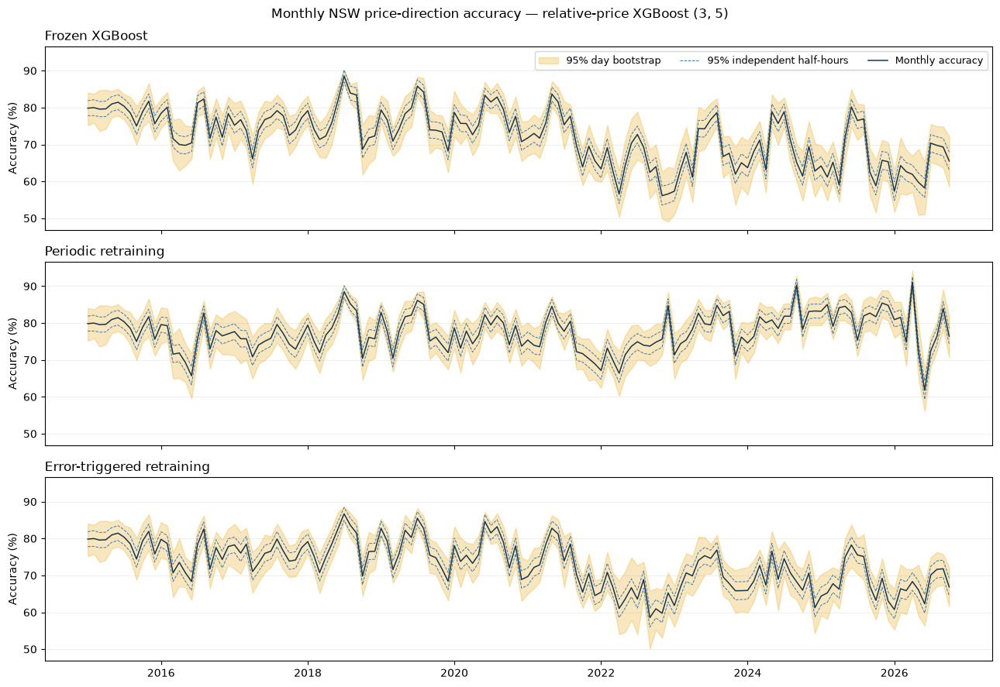

各策略的月度 95% 区间平均宽度（百分点）


,Independent half-hours,Day bootstrap
Strategy,,
Error-triggered retraining,4.49,10.00
Frozen XGBoost,4.52,10.47
Last week baseline,4.62,11.24
Periodic retraining,4.22,9.02
Yesterday baseline,4.46,8.44


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 复用上一格的逐日预测，统一报告里的名称
report = stage2_predictions.rename(columns={
    "XGBoost (3, 5) 全期冻结": "Frozen XGBoost",
    "XGBoost (3, 5) 每两年重训": "Periodic retraining",
    "相对电价 XGBoost：误差触发重训": "Error-triggered retraining",
}).copy()

report["day"] = pd.to_datetime(report["day"]).dt.normalize()
models = [
    "Frozen XGBoost", "Periodic retraining", "Error-triggered retraining",
    "Yesterday baseline", "Last week baseline",
]

# 整天抽样要求每一天有 48 个不同的半小时时段
day_sizes = report.groupby("day")["period"].agg(["size", "nunique"])
assert day_sizes.eq(48).all().all(), "有日期缺少时段或存在重复时段"
assert report[["y_up", *models]].notna().all().all(), "标签或预测存在缺失"

# 1. 年度表：每个指标都用该年全部半小时重新计算
annual_rows = []
for year, group in report.groupby(report["day"].dt.year):
    actual = group["y_up"]
    for name in models:
        annual_rows.append({
            "Year": year,
            "Strategy": name,
            "Accuracy (%)": 100 * group[name].eq(actual).mean(),
            "Balanced Accuracy (%)": balanced_accuracy(actual, group[name]),
        })

annual_results = pd.DataFrame(annual_rows)
display(annual_results.pivot(
    index="Year", columns="Strategy",
    values=["Accuracy (%)", "Balanced Accuracy (%)"]
).round(2))

# 2. 月度 Accuracy 和两种 95% 区间
# 每天都有 48 个时段，因此对整天准确率抽样等价于抽取完整的 48 条记录
correct = report[models].eq(report["y_up"], axis=0)
daily_accuracy = correct.groupby(report["day"]).mean().sort_index()

rng = np.random.default_rng(42)
monthly_rows = []

for month, days in daily_accuracy.groupby(daily_accuracy.index.to_period("M")):
    values = days.to_numpy()                   # 日期 × 模型
    n_days = len(days)
    n_intervals = 48 * n_days
    accuracy = values.mean(axis=0)

    margin = 1.96 * np.sqrt(accuracy * (1 - accuracy) / n_intervals)
    iid_low = np.clip(accuracy - margin, 0, 1)
    iid_high = np.clip(accuracy + margin, 0, 1)

    sampled_days = rng.integers(0, n_days, size=(2000, n_days))
    boot_accuracy = values[sampled_days].mean(axis=1)
    boot_low, boot_high = np.quantile(boot_accuracy, [0.025, 0.975], axis=0)

    for j, name in enumerate(models):
        monthly_rows.append({
            "Month": month.to_timestamp(),
            "Strategy": name,
            "Accuracy": 100 * accuracy[j],
            "IID low": 100 * iid_low[j],
            "IID high": 100 * iid_high[j],
            "Day low": 100 * boot_low[j],
            "Day high": 100 * boot_high[j],
        })

monthly_results = pd.DataFrame(monthly_rows)

# 3. 三种策略各画一幅图，共用坐标，便于比较
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, sharey=True)
for ax, name in zip(axes, models[:3]):
    m = monthly_results.loc[monthly_results["Strategy"].eq(name)]
    x = m["Month"].to_numpy()
    ax.fill_between(x, m["Day low"], m["Day high"],
                    color="#e69f00", alpha=0.25, label="95% day bootstrap")
    ax.plot(x, m["IID low"], color="#4078a8", lw=0.7, ls="--",
            label="95% independent half-hours")
    ax.plot(x, m["IID high"], color="#4078a8", lw=0.7, ls="--")
    ax.plot(x, m["Accuracy"], color="#18354b", lw=1.1, label="Monthly accuracy")
    ax.set_title(name, loc="left")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(axis="y", alpha=0.2)

axes[0].legend(ncol=3, fontsize=9)
fig.suptitle("Monthly NSW price-direction accuracy — relative-price XGBoost (3, 5)")
fig.tight_layout()
plt.show()

monthly_results["Independent half-hours"] = monthly_results["IID high"] - monthly_results["IID low"]
monthly_results["Day bootstrap"] = monthly_results["Day high"] - monthly_results["Day low"]
print("各策略的月度 95% 区间平均宽度（百分点）")
display(monthly_results.groupby("Strategy")[
    ["Independent half-hours", "Day bootstrap"]
].mean().round(2))

## Price report exports
Live-week estimates use historical November and December weeks. The interval describes historical variability. A market shift or exceptional price spike may move the live score outside it. The two plotted weeks illustrate extremes.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

out = Path("results/price")
out.mkdir(parents=True, exist_ok=True)
keys = ["day", "period"]

def indexed(frame):
    frame = frame.copy()
    frame["day"] = pd.to_datetime(frame["day"]).dt.normalize()
    return frame.set_index(keys, verify_integrity=True).sort_index()

scores = indexed(report)
for frame in (frozen_predictions, ensemble_check):
    other = indexed(frame)
    assert other.index.equals(scores.index)
    assert np.array_equal(scores["y_up"], other["y_up"])
    scores = scores.join(other.loc[:, ~other.columns.isin(scores.columns)])

# Evaluate fitted validation candidates on historical rows without fitting again.
history_inputs = indexed(sim).loc[scores.index].reset_index()
for label, cols in feature_sets.items():
    for family, candidate in (("MLP", fitted_mlps[label]), ("XGBoost", xgb_feature_models[label])):
        name = family + " / " + label.removeprefix("MLP ")
        scores[name] = candidate.predict(history_inputs[cols])
scores["MLP / NSW holiday"] = mlp_holiday.predict(add_public_holiday(history_inputs))
scores["XGBoost / yesterday rank"] = xgb_rank.predict(relative_features_with_rank(history_inputs))
for (depth, weight), candidate in tuned_models.items():
    scores[f"Relative XGBoost / depth {depth}, child weight {weight}"] = candidate.predict(
        relative_price_features(history_inputs))

assert scores.isin([0, 1]).all().all()
methods = scores.columns.drop("y_up")
days = scores.index.get_level_values("day")
truth = scores["y_up"]

def summarize(group):
    actual = group["y_up"]
    correct = group[methods].eq(actual, axis="index")
    recalls = correct.groupby(actual).mean()
    return pd.DataFrame({
        "Accuracy (%)": correct.mean() * 100,
        "Balanced Accuracy (%)": recalls.mean() * 100,
        "Recall 1 (%)": recalls.reindex([1]).iloc[0] * 100,
        "Recall 0 (%)": recalls.reindex([0]).iloc[0] * 100,
        "Actual positive (%)": actual.mean() * 100,
    }).rename_axis("Model")

for freq, filename in (("Y", "annual"), ("M", "monthly")):
    tables = []
    rng = np.random.default_rng(42)
    for period, block in scores.groupby(days.to_period(freq)):
        stats = summarize(block)
        stats.insert(0, "Period", str(period))
        if freq == "M":
            correct = block[methods].eq(block["y_up"], axis="index")
            daily = correct.groupby(level="day").mean().to_numpy()
            p = correct.mean()
            margin = 1.96 * np.sqrt(p * (1 - p) / len(block))
            stats["IID low (%)"] = 100 * (p - margin).clip(lower=0)
            stats["IID high (%)"] = 100 * (p + margin).clip(upper=1)
            weights = rng.multinomial(len(daily), np.full(len(daily), 1 / len(daily)), size=2000)
            low, high = np.quantile(weights @ daily / len(daily), [0.025, 0.975], axis=0)
            stats["Day bootstrap low (%)"] = 100 * low
            stats["Day bootstrap high (%)"] = 100 * high
        tables.append(stats)
    pd.concat(tables).to_csv(out / f"{filename}.csv")

weeks = []
selected = "Periodic retraining"
for week, block in scores.groupby(days.to_period("W-SUN")):
    if len(block) == 7 * 48:
        row = summarize(block).loc[selected].to_dict()
        weeks.append({"Week starts": week.start_time, **row})
weekly = pd.DataFrame(weeks).set_index("Week starts")
weekly.to_csv(out / "weekly_periodic.csv")
# Complete Mon–Sun weeks starting in Nov/Dec 2018–2025 represent recent early summers.
comparable = weekly.loc[(weekly.index.year >= 2018) & weekly.index.month.isin([11, 12])
                        & (weekly.index.year <= 2025), "Balanced Accuracy (%)"]
forecast = comparable.quantile([0.025, 0.5, 0.975])
forecast.index = ["Empirical low", "Median forecast", "Empirical high"]
forecast.to_csv(out / "live_week_price_forecast.csv", header=["Balanced accuracy (%)"])
print(f"Live week 7–13 Dec 2026: {forecast.iloc[1]:.2f}% BA; historical 95% range "
      f"{forecast.iloc[0]:.2f}–{forecast.iloc[2]:.2f}% ({len(comparable)} comparable weeks).")

metric = "Balanced Accuracy (%)"
examples = [("Lowest historical BA", weekly[metric].idxmin()),
            ("Highest historical BA", weekly[metric].idxmax())]
fig, axes = plt.subplots(2, 1, figsize=(13, 5), constrained_layout=True)
for ax, (label, start) in zip(axes, examples):
    block = scores.loc[(days >= start) & (days < start + pd.Timedelta(days=7))]
    for name, offset, color in [("y_up", 0, "black"), (selected, 0.06, "tab:blue")]:
        ax.step(np.arange(len(block)), block[name] + offset, where="mid", lw=0.9,
                label="Observed" if name == "y_up" else "Predicted (offset for visibility)", color=color)
    ax.set(title=f"{label}: week of {start.date()} ({weekly.loc[start, metric]:.1f}%)",
           xlabel="Half-hour of week", ylabel="Price class", yticks=[0, 1])
    ax.legend(loc="upper right")
fig.savefig(out / "observed_vs_predicted.png", dpi=150)
plt.show()
strategy_table = summarize(scores).loc[models].copy()
strategy_table["Retrains"] = [0, len(retrain_log), updates, 0, 0]
strategy_table.to_csv(out / "strategy_comparison.csv")
pd.DataFrame(signals).to_csv(out / "error_detector_events.csv", index=False)
signal_dates.to_csv(out / "drift_signal_dates.csv")
xgb_feature_comparison.to_csv(out / "feature_comparison_2014.csv", index=False)
tuning_2014.to_csv(out / "tuning_2014.csv", index=False)
print("Saved to", out.resolve())
